# FACE IT 2026 · Hands-on Mini Project — ECG Signal Processing & Arrhythmia Classification

**Student (GitHub):** `EaindrayMFU26` &nbsp;|&nbsp; **Notebook:** `EaindrayMFU26_ECG_Mini_Project.ipynb`

**Data:** PhysioNet AHA Database (`ahadb` v1.0.0), record **0001**, **second channel**, fs = **250 Hz**, first **1 minute**.

| Step | Task | Signal used |
|---|---|---|
| 1 | Data acquisition & raw-signal plot | first 10 s |
| 2 | FIR band-stop filtering (50 Hz) & comparison | first 10 s |
| 3 | R-peak detection (Pan–Tompkins) | first 10 s |
| 4 | Heart-rate & rhythm classification | full 1 min |
| 5 | Feature extraction (RR interval, QRS duration) per 10-s segment | full 1 min |
| 6 | Machine-learning classification (SVM): Normal vs Arrhythmia | features |

In [1]:
# Step 0.1 — Student identity and working environment | EaindrayMFU26
import sys, platform, datetime
from pathlib import Path
import numpy, scipy, matplotlib, pandas, sklearn, wfdb

STUDENT = "EaindrayMFU26"
print(f"Student (GitHub) : {STUDENT}")
print(f"Project          : FACE IT 2026 - Hands-on Mini Project (ECG, AHA DB record 0001)")
print(f"Run at           : {datetime.datetime.now(datetime.timezone.utc):%Y-%m-%d %H:%M} UTC")
print(f"Python           : {sys.version.split()[0]} "
      f"({platform.system()} {platform.machine()})")
print(f"Working folder   : {Path.cwd()}")
for m in (numpy, scipy, matplotlib, pandas, sklearn, wfdb):
    print(f"{m.__name__:<17}: {m.__version__}")

Student (GitHub) : EaindrayMFU26
Project          : FACE IT 2026 - Hands-on Mini Project (ECG, AHA DB record 0001)
Run at           : 2026-10-15 14:33 UTC
Python           : 3.13.16 (Linux x86_64)
Working folder   : /home/user/FACE-IT-2026-ECG-Mini-Project
numpy            : 2.5.3
scipy            : 1.18.1
matplotlib       : 3.11.2
pandas           : 3.0.5
sklearn          : 1.9.1
wfdb             : 4.3.1


In [2]:
# Step 0.2 — Imports, constants and plotting style | EaindrayMFU26
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.integrate import trapezoid
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, classification_report

FS = 250            # sampling frequency (Hz), as specified in the assignment
CHANNEL = 1         # second signal column/channel (Python index starts at 0)
SEED = 42           # fixed random seed -> reproducible train/test split
DATA, FIG, RES = Path("data"), Path("figures"), Path("results")
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)

# colour roles (validated colour-blind-safe categorical palette) and quiet chart chrome
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, RAW = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Inter", "Arial", "DejaVu Sans"],
    "font.size": 9.5, "axes.titlesize": 11, "axes.titleweight": "semibold",
    "axes.titlelocation": "left", "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "legend.frameon": False,
    "legend.labelcolor": INK2, "figure.dpi": 110, "figure.facecolor": "white"})

def save(fig, name):
    """Save a figure for the report (200 dpi PNG) in the figures/ folder."""
    fig.savefig(FIG / name, dpi=200, bbox_inches="tight", facecolor="white")

## Step 1 — Data acquisition and visualization (first 10 s)

Record 0001 of the PhysioNet AHA Database is read with the `wfdb` package.
The files in `data/ahadb/` are the original PhysioNet files (`0001.hea`, `0001.dat`, `0001.atr`),
obtained from PhysioNet's official open-data mirror, and their integrity is checked against
PhysioNet's published `SHA256SUMS.txt`.

In [3]:
# Step 1.1 — Import AHA Database record 0001 from PhysioNet | EaindrayMFU26
rec_dir = DATA / "ahadb"
sha_lines = (rec_dir / "SHA256SUMS.txt").read_text().splitlines()
sums = {name: digest for digest, name in (line.split() for line in sha_lines if line.strip())}
for f in ("0001.hea", "0001.dat", "0001.atr"):
    ok = hashlib.sha256((rec_dir / f).read_bytes()).hexdigest() == sums[f]
    print(f"{f:<9} SHA-256 matches PhysioNet: {ok}")

header = wfdb.rdheader(str(rec_dir / "0001"))
record = wfdb.rdrecord(str(rec_dir / "0001"), sampto=60 * FS)     # first 1 minute
# online alternative: wfdb.rdrecord("0001", pn_dir="ahadb", sampto=60 * FS)
assert record.fs == FS
print(f"\nRecord {header.record_name}: {header.n_sig} signals, fs = {header.fs} Hz, "
      f"full length = {header.sig_len / header.fs / 3600:.1f} h")
print("Signals:", header.sig_name, "| units:", header.units, "| ADC gain:", header.adc_gain)

0001.hea  SHA-256 matches PhysioNet: True
0001.dat  SHA-256 matches PhysioNet: True
0001.atr  SHA-256 matches PhysioNet: True

Record 0001: 2 signals, fs = 250 Hz, full length = 3.0 h
Signals: ['ECG', 'ECG'] | units: ['mV', 'mV'] | ADC gain: [400.0, 400.0]


In [4]:
# Step 1.2 — Second channel: 1-minute and 10-second signals | EaindrayMFU26
ecg60 = record.p_signal[:, CHANNEL]                 # 1-minute ECG (mV), 15 000 samples
t60 = np.arange(ecg60.size) / FS                    # time axis (s)
ecg10, t10 = ecg60[:10 * FS], t60[:10 * FS]         # first 10 s, 2 500 samples
print(f"Channel used : column {CHANNEL + 1} of {record.n_sig} "
      f"({record.sig_name[CHANNEL]}, {record.units[CHANNEL]})")
print(f"Samples      : 1 min = {ecg60.size}, 10 s = {ecg10.size}")
pd.DataFrame({"first 10 s": pd.Series(ecg10).describe(),
              "full 60 s": pd.Series(ecg60).describe()}).round(3).T

Channel used : column 2 of 2 (ECG, mV)
Samples      : 1 min = 15000, 10 s = 2500


,count,mean,std,min,25%,50%,75%,max
first 10 s,2500.0,-0.100,0.318,-1.872,-0.180,-0.068,0.021,2.998
full 60 s,15000.0,-0.147,0.271,-1.948,-0.208,-0.128,-0.048,3.188


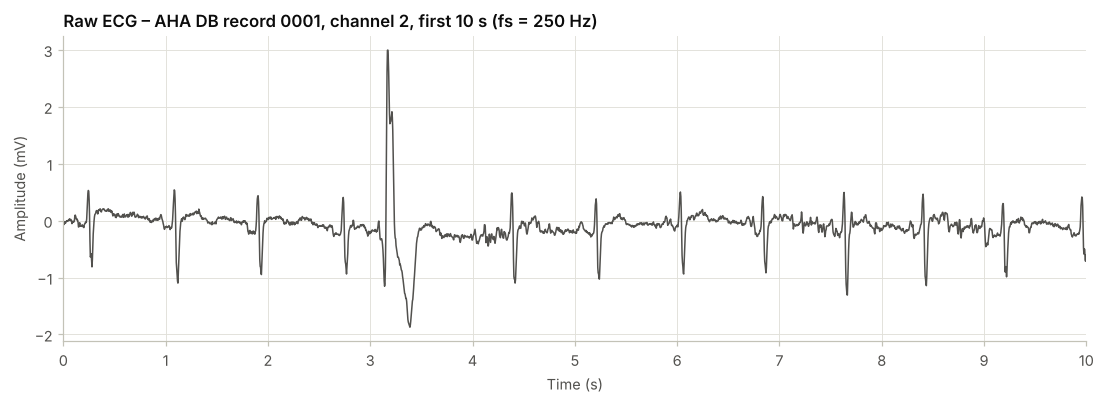

In [5]:
# Step 1.3 — Plot the raw ECG (first 10 s) | EaindrayMFU26
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(t10, ecg10, color=RAW, lw=1.0)
ax.set(title="Raw ECG – AHA DB record 0001, channel 2, first 10 s (fs = 250 Hz)",
       xlabel="Time (s)", ylabel="Amplitude (mV)", xlim=(0, 10))
ax.set_xticks(np.arange(0, 10.1, 1))
save(fig, "fig01_raw_ecg_10s.png"); plt.show()

## Step 2 — ECG filtering with an FIR band-stop filter (first 10 s)

**Design.** Power-line interference is a narrow-band sinusoid, so a **band-stop (notch-type) FIR filter**
centred on **50 Hz** is used: cut-off frequencies 48 Hz and 52 Hz, Kaiser window designed for ≥ 40 dB
attenuation with a 2-Hz transition band (`scipy.signal.kaiserord` + `firwin`). An FIR filter with
symmetric coefficients has **linear phase**, and it is applied forward–backward (`filtfilt`), so the
output has **zero phase shift** – the P-QRS-T waves are not displaced in time.

FIR band-stop: 281 taps, Kaiser beta = 3.40, cut-offs 48 / 52 Hz
Attenuation at 50 Hz: 38.2 dB per pass -> 76.4 dB with filtfilt
Max pass-band ripple (<= 46 Hz and >= 54 Hz): 0.062 dB
Group delay 0.56 s -> cancelled by filtfilt (zero phase)


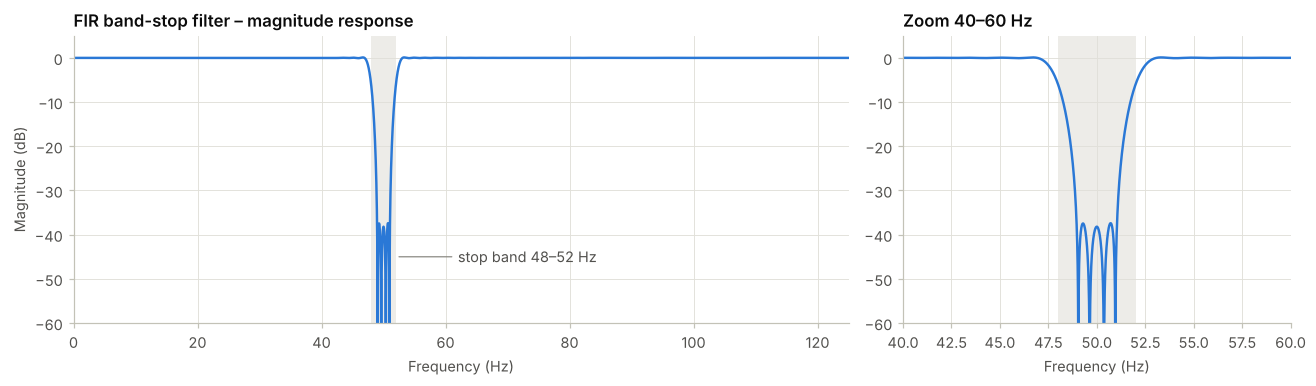

In [6]:
# Step 2.1 — Design the FIR band-stop filter (50 Hz) | EaindrayMFU26
F0, HALF_BW = 50.0, 2.0              # stop band centred on 50 Hz -> cut-offs 48 and 52 Hz
ATTEN_DB, TRANS_HZ = 40.0, 2.0       # Kaiser design: >= 40 dB attenuation, 2-Hz transition
numtaps, beta = signal.kaiserord(ATTEN_DB, TRANS_HZ / (FS / 2))
numtaps += numtaps % 2 == 0          # band-stop FIR needs an odd length (type-I linear phase)
h_bs = signal.firwin(numtaps, [F0 - HALF_BW, F0 + HALF_BW], window=("kaiser", beta),
                     pass_zero="bandstop", fs=FS)

f_h, H = signal.freqz(h_bs, worN=16384, fs=FS)
H_db = 20 * np.log10(np.abs(H) + 1e-12)
att50 = -H_db[np.argmin(np.abs(f_h - 50))]
ripple = np.abs(H_db[(f_h <= 46) | (f_h >= 54)]).max()
print(f"FIR band-stop: {numtaps} taps, Kaiser beta = {beta:.2f}, cut-offs 48 / 52 Hz")
print(f"Attenuation at 50 Hz: {att50:.1f} dB per pass -> {2 * att50:.1f} dB with filtfilt")
print(f"Max pass-band ripple (<= 46 Hz and >= 54 Hz): {ripple:.3f} dB")
print(f"Group delay {(numtaps - 1) / 2 / FS:.2f} s -> cancelled by filtfilt (zero phase)")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [2, 1]})
for ax, (lo, hi) in ((a1, (0, FS / 2)), (a2, (40, 60))):
    ax.axvspan(48, 52, color=GRID, alpha=0.6, lw=0)
    ax.plot(f_h, H_db, color=BLUE, lw=1.6)
    ax.set(xlim=(lo, hi), ylim=(-60, 5), xlabel="Frequency (Hz)")
a1.set(title="FIR band-stop filter – magnitude response", ylabel="Magnitude (dB)")
a2.set(title="Zoom 40–60 Hz")
a1.annotate("stop band 48–52 Hz", (52, -45), xytext=(62, -45), color=INK2,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8), va="center")
fig.tight_layout(); save(fig, "fig02_fir_bandstop_response.png"); plt.show()

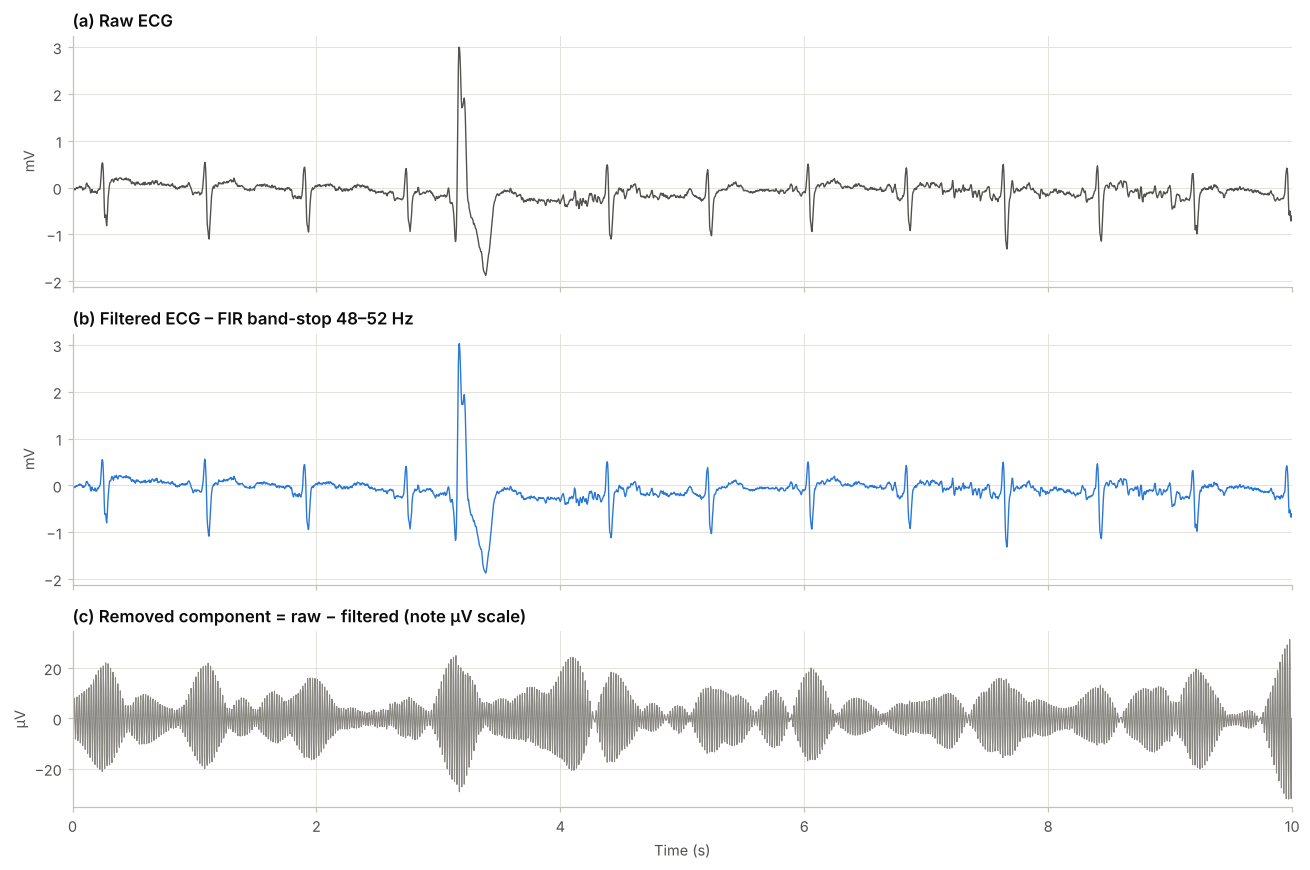

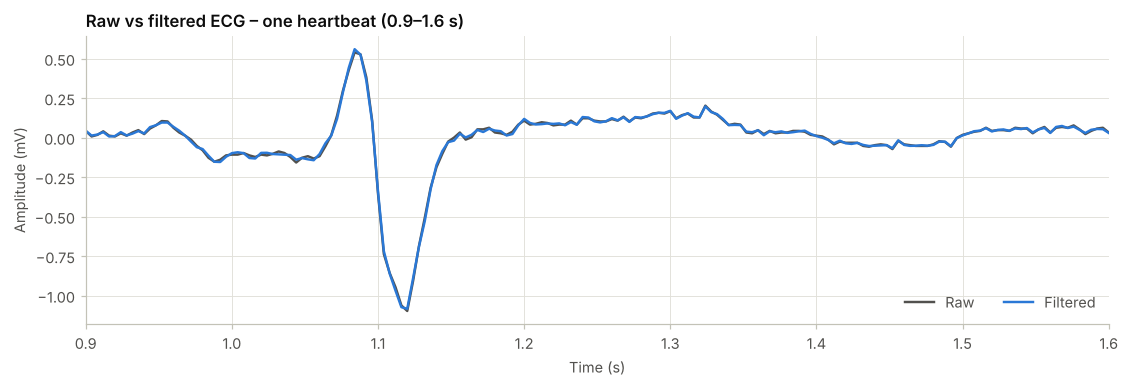

In [7]:
# Step 2.2 — Apply the filter to the first 10 s and compare with the raw ECG | EaindrayMFU26
def bandstop(x):
    """Zero-phase FIR band-stop filtering (forward-backward, no phase distortion)."""
    return signal.filtfilt(h_bs, 1.0, x)

ecg10_f = bandstop(ecg10)
removed = ecg10 - ecg10_f                       # what the filter took out

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True,
                         gridspec_kw={"height_ratios": [1, 1, 0.7]})
axes[0].plot(t10, ecg10, color=RAW, lw=0.9)
axes[0].set(title="(a) Raw ECG", ylabel="mV")
axes[1].plot(t10, ecg10_f, color=BLUE, lw=0.9)
axes[1].set(title="(b) Filtered ECG – FIR band-stop 48–52 Hz", ylabel="mV")
axes[1].set_ylim(axes[0].get_ylim())
axes[2].plot(t10, removed * 1000, color=MUTED, lw=0.7)
axes[2].set(title="(c) Removed component = raw − filtered (note µV scale)",
            ylabel="µV", xlabel="Time (s)", xlim=(0, 10))
fig.tight_layout(); save(fig, "fig03_raw_vs_filtered_10s.png"); plt.show()

z = (t10 >= 0.9) & (t10 <= 1.6)                  # one heartbeat, overlaid
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.plot(t10[z], ecg10[z], color=RAW, lw=1.6, label="Raw")
ax.plot(t10[z], ecg10_f[z], color=BLUE, lw=1.6, label="Filtered")
ax.set(title="Raw vs filtered ECG – one heartbeat (0.9–1.6 s)", xlabel="Time (s)",
       ylabel="Amplitude (mV)", xlim=(0.9, 1.6))
ax.legend(loc="lower right", ncol=2)
save(fig, "fig03b_raw_vs_filtered_zoom.png"); plt.show()

50-Hz peak above neighbouring noise floor, raw (dB)        3.479
Power 49-51 Hz, raw (µV²)                                  18.97
Power 49-51 Hz, filtered (µV²)                         2.186e-05
Power reduction 49-51 Hz (dB)                              59.39
RMS raw ECG (µV)                                           318.2
RMS removed component (µV)                                 8.144
Removed / raw RMS (%)                                       2.56
Correlation raw vs filtered                               0.9997


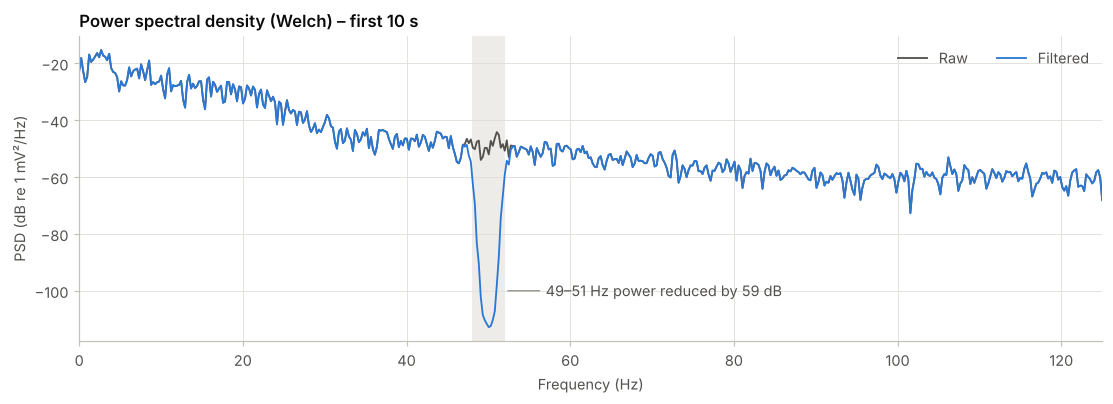

In [8]:
# Step 2.3 — Quantify the effect of the filter (spectrum, statistics) | EaindrayMFU26
f_p, P_raw = signal.welch(ecg10 - ecg10.mean(), fs=FS, nperseg=1024)
_, P_flt = signal.welch(ecg10_f - ecg10_f.mean(), fs=FS, nperseg=1024)
band = (f_p >= 49) & (f_p <= 51)
side = ((f_p > 44) & (f_p < 47)) | ((f_p > 53) & (f_p < 56))
rms = lambda v: np.sqrt(np.mean((v - v.mean()) ** 2))
pw_raw = trapezoid(P_raw[band], f_p[band]) * 1e6          # µV²
pw_flt = trapezoid(P_flt[band], f_p[band]) * 1e6
filter_stats = pd.Series({
    "50-Hz peak above neighbouring noise floor, raw (dB)":
        10 * np.log10(P_raw[band].max() / np.median(P_raw[side])),
    "Power 49-51 Hz, raw (µV²)": pw_raw,
    "Power 49-51 Hz, filtered (µV²)": pw_flt,
    "Power reduction 49-51 Hz (dB)": 10 * np.log10(pw_raw / pw_flt),
    "RMS raw ECG (µV)": rms(ecg10) * 1000,
    "RMS removed component (µV)": rms(removed) * 1000,
    "Removed / raw RMS (%)": 100 * rms(removed) / rms(ecg10),
    "Correlation raw vs filtered": np.corrcoef(ecg10, ecg10_f)[0, 1]})
filter_stats.to_csv(RES / "step2_filter_effect.csv", header=["value"])
print(filter_stats.map(lambda v: f"{v:.4g}").to_string())

fig, ax = plt.subplots(figsize=(12, 3.6))
ax.axvspan(48, 52, color=GRID, alpha=0.6, lw=0)
ax.plot(f_p, 10 * np.log10(P_raw), color=RAW, lw=1.2, label="Raw")
ax.plot(f_p, 10 * np.log10(P_flt), color=BLUE, lw=1.2, label="Filtered")
ax.annotate(f"49–51 Hz power reduced by {filter_stats.iloc[3]:.0f} dB", (52, -100),
            xytext=(57, -100), color=INK2, va="center",
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.set(title="Power spectral density (Welch) – first 10 s", xlabel="Frequency (Hz)",
       ylabel="PSD (dB re 1 mV²/Hz)", xlim=(0, FS / 2))
ax.legend(loc="upper right", ncol=2)
save(fig, "fig04_psd_raw_vs_filtered.png"); plt.show()

**Does the filtering visibly improve the signal?** *Only marginally – because there is very little
50-Hz interference to remove.* In the raw spectrum the 50-Hz peak is only ≈ 3.5 dB above the neighbouring
noise floor. The filter works exactly as designed – the power in the 49–51 Hz band drops by ≈ 59 dB
(deep notch in the PSD) – but the removed component is tiny (RMS ≈ 8 µV, ≈ 2.6 % of the ECG RMS of
≈ 318 µV), so the raw and filtered traces are practically identical (correlation 0.9997). Importantly,
the P-QRS-T morphology and the timing of the waves are preserved (zero-phase filtering, no distortion).
The disturbances that are *visible* in the raw trace – slow baseline wander and broadband muscle noise –
lie outside the 48–52 Hz stop band; removing them would need a high-pass (≈ 0.5 Hz) and a low-pass
(≈ 40 Hz) filter. (The AHA recordings come from the USA, where the mains frequency is 60 Hz; setting
`F0 = 60` re-targets the same design, and the spectrum shows no dominant 60-Hz line either.)

## Step 3 — R-peak detection (first 10 s)

**Method: Pan–Tompkins algorithm** applied to the band-stop-filtered ECG:
1. band-pass 5–15 Hz (QRS energy band) → 2. five-point derivative (slopes) → 3. squaring
→ 4. 150-ms moving-window integration (MWI) → 5. adaptive thresholds on the MWI peaks
(signal/noise levels, 200-ms refractory period, T-wave check within 360 ms, search-back for missed beats).

The **R-peak** is then located as the maximum of the filtered ECG around each detected QRS.
Two simple **plausibility checks** make the detector robust to a muscle-noise burst that occurs later in
the recording: (a) a detection that splits one normal RR interval in two is removed (the one that least
resembles the median beat), and (b) a beat that poorly matches the median beat template is re-located to
the best match within ±150 ms. Each beat is labelled *Normal*, *Ectopic (PVC-like)* (premature, followed by a
compensatory pause, abnormal and > 2× larger complex) or *Low-confidence (noise)*.

In [9]:
# Step 3.1 — R-peak detector: Pan-Tompkins + plausibility checks | EaindrayMFU26
def pan_tompkins(ecg, fs, pad_s=0.5):
    """Pan & Tompkins (1985) QRS detector -> MWI peak indices and intermediate signals."""
    pad = int(pad_s * fs)
    x = np.pad(ecg, pad, mode="reflect")                        # mirror padding (edge beats)
    b, a = signal.butter(2, [5, 15], btype="bandpass", fs=fs)
    bp = signal.filtfilt(b, a, x)                                # 1) band-pass 5-15 Hz
    der = np.convolve(bp, np.array([1, 2, 0, -2, -1]) * fs / 8, mode="same")  # 2) derivative
    sq = der ** 2                                                # 3) squaring
    w = int(round(0.150 * fs))
    mwi = np.convolve(sq, np.ones(w) / w, mode="same")           # 4) 150-ms integration
    cand, _ = signal.find_peaks(mwi, distance=int(0.200 * fs))   # 200-ms refractory period
    spki, npki = 0.25 * mwi[:2 * fs].max(), 0.5 * mwi[:2 * fs].mean()   # 2-s learning phase
    thr, qrs, noise, thr_hist = npki + 0.25 * (spki - npki), [], [], []
    slope = lambda i: np.abs(der[max(0, i - int(0.075 * fs)):i + int(0.075 * fs)]).max()
    for c in cand:                                               # 5) adaptive thresholds
        t_wave = bool(qrs) and c - qrs[-1] < 0.36 * fs and slope(c) < 0.5 * slope(qrs[-1])
        if mwi[c] > thr and not t_wave:
            if len(qrs) >= 2 and c - qrs[-1] > 1.66 * np.median(np.diff(qrs[-9:])):
                missed = [n for n in noise if qrs[-1] + 0.2 * fs < n < c - 0.2 * fs
                          and mwi[n] > 0.5 * thr]                # search-back
                if missed:
                    qrs.append(max(missed, key=lambda n: mwi[n]))
            qrs.append(c); spki = 0.125 * mwi[c] + 0.875 * spki
        else:
            noise.append(c); npki = 0.125 * mwi[c] + 0.875 * npki
        thr = npki + 0.25 * (spki - npki); thr_hist.append((c - pad, thr))
    qrs = np.array(sorted(qrs)) - pad
    qrs = qrs[(qrs > -0.08 * fs) & (qrs < len(ecg) + 0.10 * fs)]
    stages = {k: v[pad:pad + len(ecg)]
              for k, v in dict(bp=bp, der=der, sq=sq, mwi=mwi).items()}
    stages["thr"] = np.array(thr_hist)
    return qrs, stages

def locate_r(ecg, qrs, fs):
    """R-peak = maximum of the filtered ECG from 100 ms before to 80 ms after each QRS."""
    r = []
    for c in qrs:
        lo, hi = max(0, c - int(0.10 * fs)), min(len(ecg), c + int(0.08 * fs))
        i = lo + int(np.argmax(ecg[lo:hi]))
        if not r or i - r[-1] > int(0.02 * fs):          # skip duplicates at the edges
            r.append(i)
    return np.array(r)

PRE, POST = int(0.10 * FS), int(0.15 * FS)                       # beat window around R

def detect_r_peaks(ecg, fs):
    """Pan-Tompkins -> R location -> plausibility checks -> beat labels."""
    qrs, stages = pan_tompkins(ecg, fs)
    r = list(locate_r(ecg, qrs, fs))
    seg = lambda i: ecg[i - PRE:i + POST]
    inside = lambda i: i - PRE >= 0 and i + POST <= len(ecg)
    tpl = np.median([seg(i) - np.median(seg(i)) for i in r if inside(i)], axis=0)
    corr = lambda i: np.corrcoef(seg(i), tpl)[0, 1] if inside(i) else np.nan
    while len(r) > 2:          # (a) extra detection splitting one normal RR interval
        med = np.median(np.diff(r))
        extra = [k for k in range(1, len(r) - 1) if r[k + 1] - r[k - 1] < 1.5 * med]
        if not extra:
            break
        r.pop(min(extra, key=lambda k: np.nan_to_num(corr(r[k]), nan=1.0)))
    r = np.array(r); moved = np.zeros(len(r), bool)
    for k, i in enumerate(r):  # (b) re-locate a poorly matching beat (best match +-150 ms)
        c0 = corr(i)
        if np.isnan(c0) or c0 >= 0.6:
            continue
        js = np.arange(max(PRE, i - int(0.15 * fs)), min(len(ecg) - POST, i + int(0.15 * fs)))
        cs = np.array([corr(j) for j in js])
        if cs.max() >= 0.6 and cs.max() - c0 >= 0.1:
            r[k], moved[k] = js[cs.argmax()], True
    cc = np.array([corr(i) for i in r])                          # (c) beat labels
    rr_pre, rr_post = np.r_[np.nan, np.diff(r)] / fs, np.r_[np.diff(r), np.nan] / fs
    amp = np.array([np.ptp(ecg[max(0, i - PRE):i + POST]) for i in r])
    med_rr = np.median(np.diff(r)) / fs
    ectopic = ((rr_pre < 0.8 * med_rr) & (rr_post > 1.2 * med_rr) & (cc < 0.5)
               & (amp / np.median(amp) > 2.0))
    label = np.where(ectopic, "Ectopic (PVC-like)",
                     np.where(cc < 0.6, "Low-confidence (noise)", "Normal"))
    beats = pd.DataFrame({"t_R (s)": r / fs, "R amplitude (mV)": ecg[r],
                          "template corr": cc.round(2), "re-located": moved,
                          "beat type": label})
    return r, beats, stages

In [10]:
# Step 3.2 — Detect R-peaks in the first 10 s of the filtered ECG | EaindrayMFU26
r10, beats10, st10 = detect_r_peaks(ecg10_f, FS)
beats10.index = pd.RangeIndex(1, len(r10) + 1, name="beat")
beats10.to_csv(RES / "step3_rpeaks_first10s.csv")
print(f"R-peaks detected in the first 10 s: {len(r10)}")
beats10.round(3)

R-peaks detected in the first 10 s: 13


,t_R (s),R amplitude (mV),template corr,re-located,beat type
beat,,,,,
1,0.244,0.551,0.98,False,Normal
2,1.084,0.560,0.98,False,Normal
3,1.900,0.443,0.98,False,Normal
4,2.736,0.407,0.99,False,Normal
5,3.172,3.027,-0.17,False,Ectopic (PVC-like)
6,4.384,0.505,0.99,False,Normal
7,5.208,0.385,0.98,False,Normal
8,6.032,0.500,0.99,False,Normal
9,6.836,0.425,0.97,False,Normal


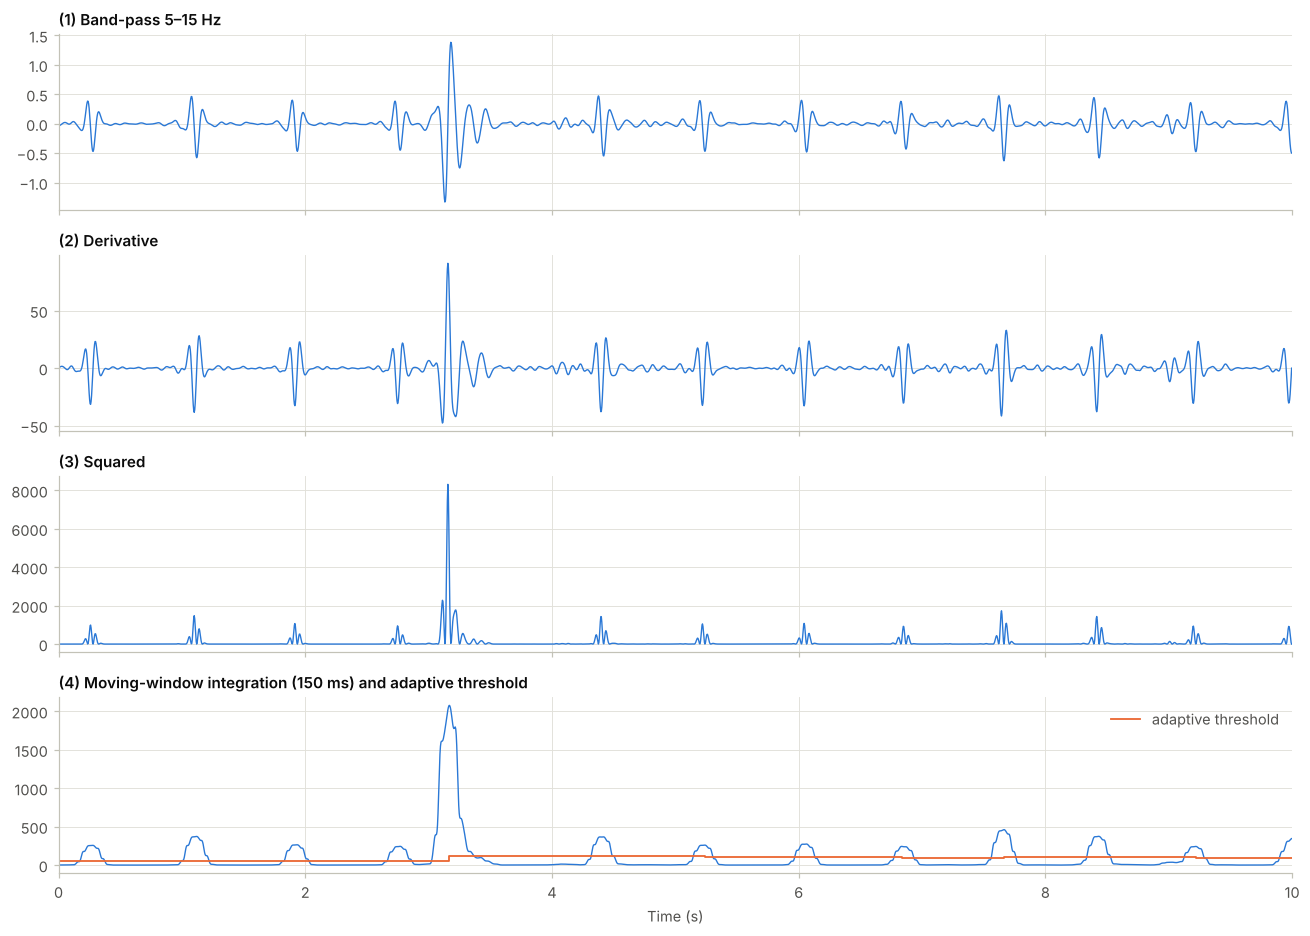

In [11]:
# Step 3.3 — Pan-Tompkins intermediate signals (first 10 s) | EaindrayMFU26
fig, axes = plt.subplots(4, 1, figsize=(12, 8.6), sharex=True)
for ax, key, title in zip(axes, ["bp", "der", "sq", "mwi"],
                          ["(1) Band-pass 5–15 Hz", "(2) Derivative", "(3) Squared",
                           "(4) Moving-window integration (150 ms) and adaptive threshold"]):
    ax.plot(t10, st10[key], color=BLUE, lw=0.9)
    ax.set_title(title, fontsize=10)
thr_t, thr_v = st10["thr"][:, 0] / FS, st10["thr"][:, 1]
axes[3].step(thr_t, thr_v, where="post", color=ORANGE, lw=1.2, label="adaptive threshold")
axes[3].legend(loc="upper right")
axes[3].set(xlabel="Time (s)", xlim=(0, 10))
fig.tight_layout(); save(fig, "fig05_pan_tompkins_stages_10s.png"); plt.show()

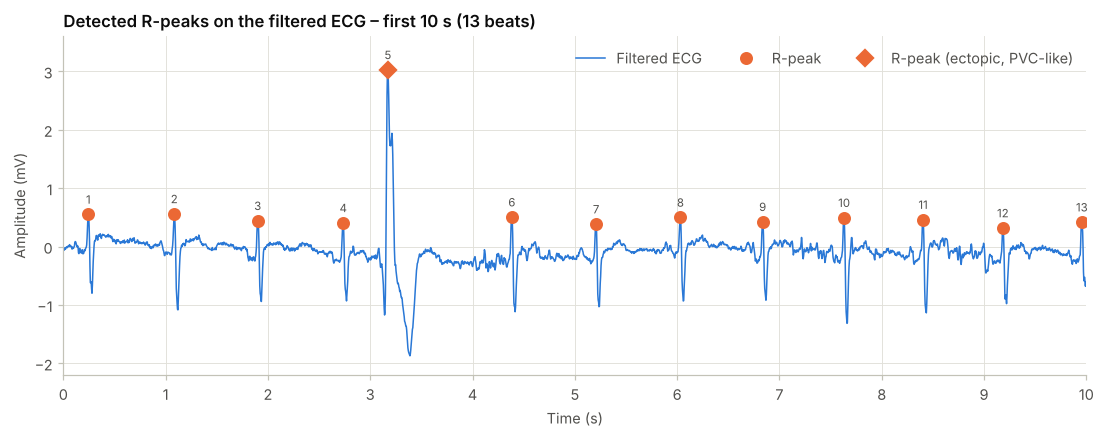

In [12]:
# Step 3.4 — Overlay the detected R-peaks on the filtered ECG (first 10 s) | EaindrayMFU26
def mark_beats(ax, t, ecg, r, labels, numbers=True):
    """R-peak markers: filled circle = normal, diamond = ectopic, ring = low-confidence."""
    styles = {"Normal": ("R-peak", dict(marker="o", mfc=ORANGE)),
              "Ectopic (PVC-like)": ("R-peak (ectopic, PVC-like)",
                                     dict(marker="D", mfc=ORANGE)),
              "Low-confidence (noise)": ("R-peak (low confidence, noise)",
                                         dict(marker="o", mfc="white"))}
    for lab, (name, sty) in styles.items():
        sel = r[labels == lab]
        if sel.size:
            ax.plot(t[sel], ecg[sel], ls="none", ms=7, mec=ORANGE, mew=1.5, label=name, **sty)
    if numbers:
        for k, i in enumerate(r, 1):
            ax.annotate(str(k), (t[i], ecg[i]), xytext=(0, 7), textcoords="offset points",
                        ha="center", fontsize=7.5, color=INK2)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t10, ecg10_f, color=BLUE, lw=1.0, label="Filtered ECG")
mark_beats(ax, t10, ecg10_f, r10, beats10["beat type"].to_numpy())
ax.set(title=f"Detected R-peaks on the filtered ECG – first 10 s ({len(r10)} beats)",
       xlabel="Time (s)", ylabel="Amplitude (mV)", xlim=(0, 10), ylim=(-2.2, 3.6))
ax.set_xticks(np.arange(0, 10.1, 1)); ax.legend(loc="upper right", ncol=3)
save(fig, "fig06_rpeaks_10s.png"); plt.show()

## Step 4 — Heart-rhythm analysis (full 1-minute recording)

The same band-stop filter and R-peak detector are applied to the complete 60-s signal.
Heart rate is computed in two equivalent ways: from the **R-peak count** (beats per minute of recording)
and from the **mean RR interval** (60 / mean RR). Classification: < 60 bpm *Bradycardia*,
60–100 bpm *Normal*, > 100 bpm *Tachycardia*.

In [13]:
# Step 4.1 — R-peaks, heart rate and rhythm classification (1 minute) | EaindrayMFU26
ecg60_f = bandstop(ecg60)
r60, beats60, st60 = detect_r_peaks(ecg60_f, FS)
types60 = beats60["beat type"].to_numpy()

def classify_hr(bpm):
    return "Bradycardia" if bpm < 60 else "Tachycardia" if bpm > 100 else "Normal"

duration_min = ecg60.size / FS / 60
n_peaks = len(r60)
rr_all = np.diff(r60) / FS
hr_count = n_peaks / duration_min                  # beats counted in 1 minute
hr_meanrr = 60 / rr_all.mean()                     # 60 / mean RR interval
hr_summary = pd.Series({
    "Recording duration (s)": ecg60.size / FS,
    "Total R-peaks detected": n_peaks,
    "  normal beats": int((types60 == "Normal").sum()),
    "  ectopic (PVC-like) beats": int((types60 == "Ectopic (PVC-like)").sum()),
    "  low-confidence beats (noise burst)": int((types60 == "Low-confidence (noise)").sum()),
    "Heart rate from count (bpm)": round(hr_count, 1),
    "Heart rate from mean RR (bpm)": round(hr_meanrr, 1),
    "Classification": classify_hr(hr_count)})
hr_summary.to_csv(RES / "step4_heart_rate.csv", header=["value"])
print(hr_summary.to_string())
print(f"\nHeart Rate = {hr_count:.0f} bpm -> {classify_hr(hr_count)}")

Recording duration (s)                    60.0
Total R-peaks detected                      76
  normal beats                              72
  ectopic (PVC-like) beats                   3
  low-confidence beats (noise burst)         1
Heart rate from count (bpm)               76.0
Heart rate from mean RR (bpm)             75.6
Classification                          Normal

Heart Rate = 76 bpm -> Normal


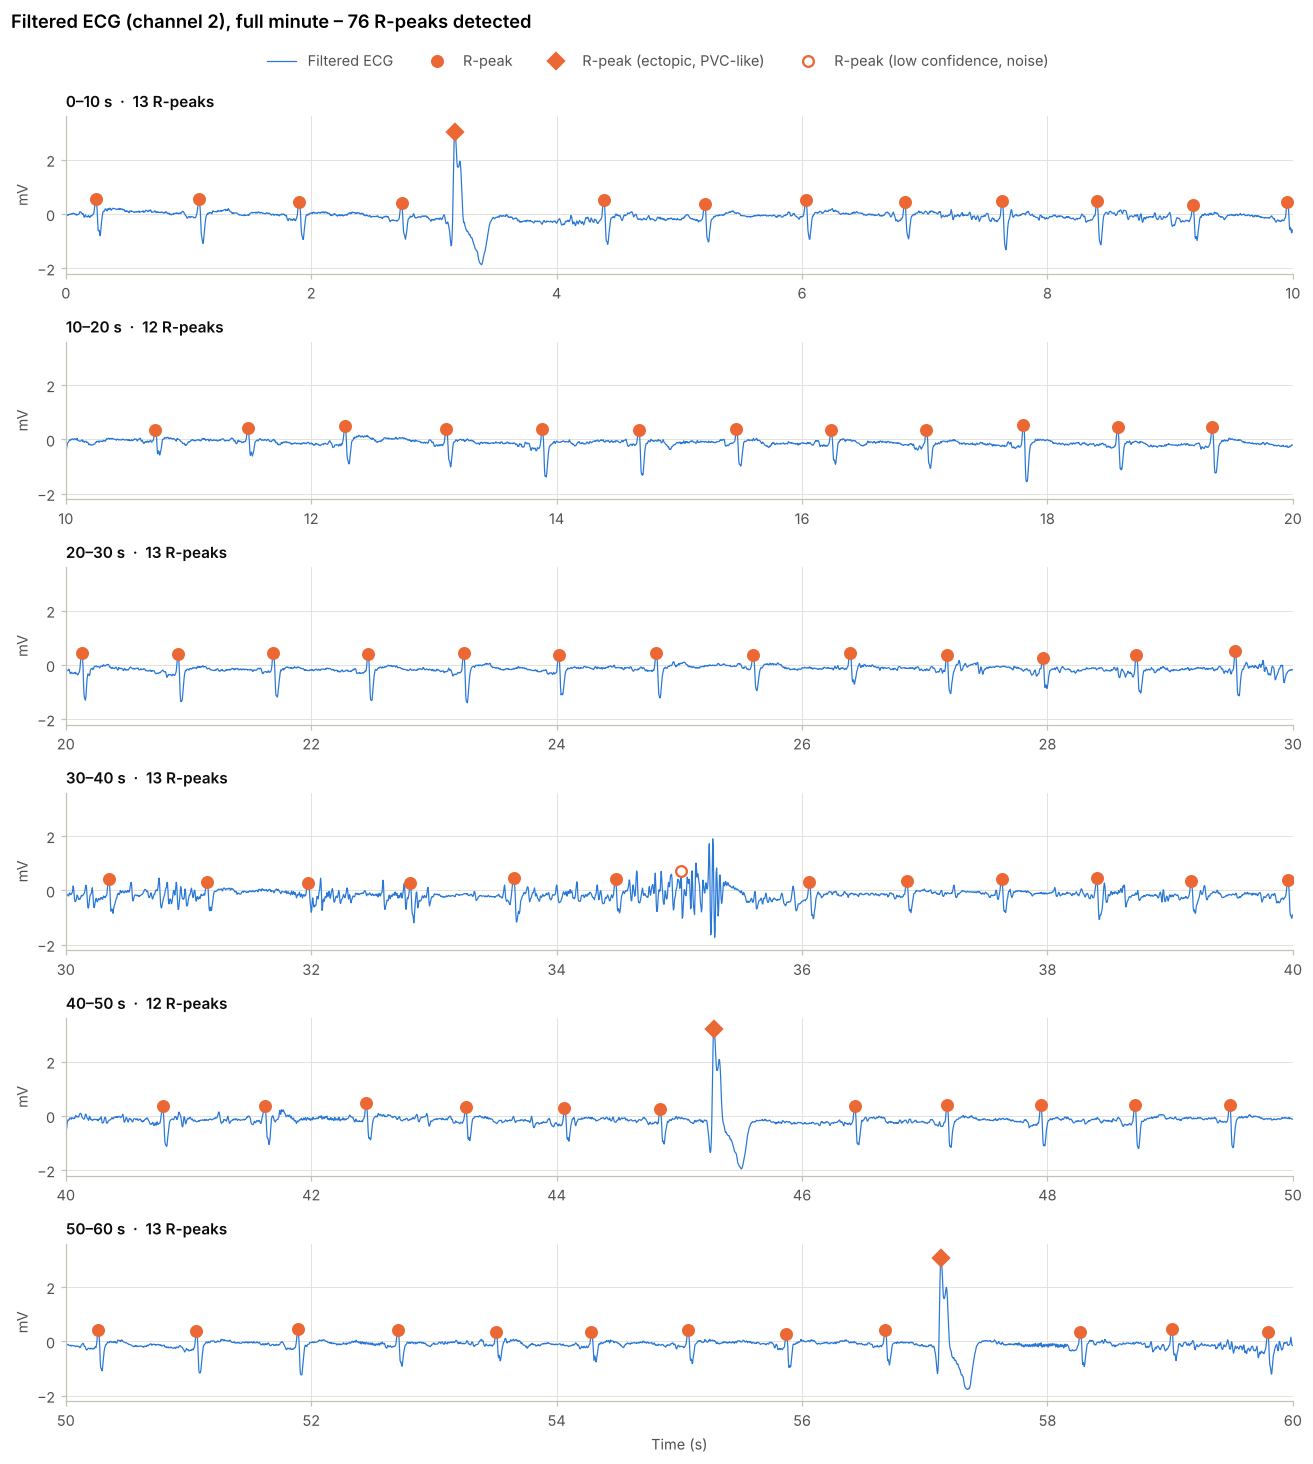

In [14]:
# Step 4.2 — The full minute with detected R-peaks (one row per 10 s) | EaindrayMFU26
fig, axes = plt.subplots(6, 1, figsize=(12, 13), sharey=True)
for k, ax in enumerate(axes):
    m = (t60 >= 10 * k) & (t60 < 10 * (k + 1))
    ax.plot(t60[m], ecg60_f[m], color=BLUE, lw=0.8, label="Filtered ECG")
    sel = (r60 >= 10 * k * FS) & (r60 < 10 * (k + 1) * FS)
    mark_beats(ax, t60, ecg60_f, r60[sel], types60[sel], numbers=False)
    ax.set_xlim(10 * k, 10 * (k + 1)); ax.set_ylim(-2.2, 3.6)
    ax.set_title(f"{10 * k}–{10 * (k + 1)} s  ·  {sel.sum()} R-peaks", fontsize=10)
    ax.set_ylabel("mV")
axes[-1].set_xlabel("Time (s)")
handles, labels = [], []
for ax in axes:                                   # one legend with every marker type
    for h, l in zip(*ax.get_legend_handles_labels()):
        if l not in labels:
            handles.append(h); labels.append(l)
fig.legend(handles, labels, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.0))
fig.suptitle(f"Filtered ECG (channel 2), full minute – {n_peaks} R-peaks detected",
             x=0.01, ha="left", fontsize=12, fontweight="semibold", y=1.02)
fig.tight_layout(); save(fig, "fig07_rpeaks_full_minute.png"); plt.show()

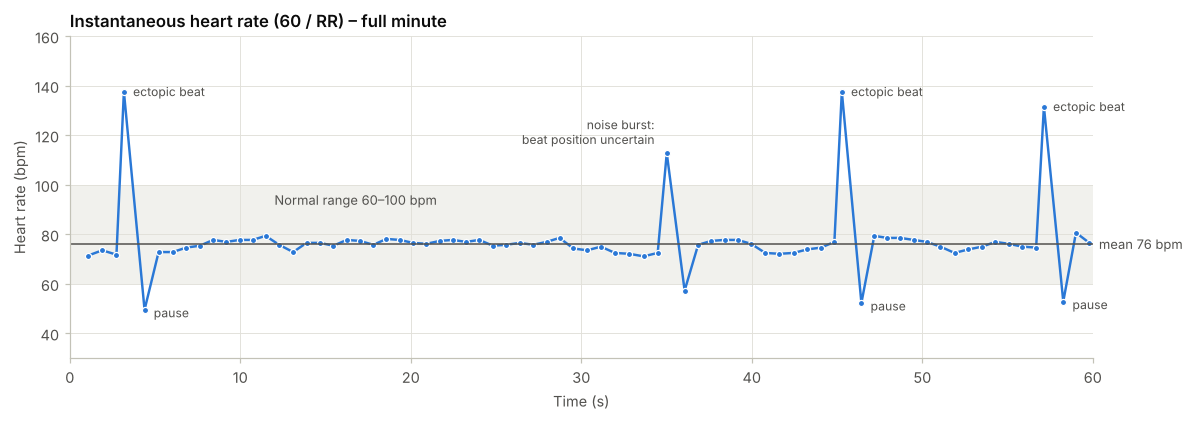

In [15]:
# Step 4.3 — Instantaneous heart rate across the minute | EaindrayMFU26
inst_hr = 60 / rr_all
t_hr = r60[1:] / FS
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.axhspan(60, 100, color=GRID, alpha=0.45, lw=0)
ax.text(12, 97, "Normal range 60–100 bpm", color=INK2, va="top", fontsize=8.5)
ax.plot(t_hr, inst_hr, color=BLUE, lw=1.6, marker="o", ms=4, mec="white", mew=0.8)
ax.axhline(hr_count, color=INK2, lw=1.0)
ax.annotate(f"mean {hr_count:.0f} bpm", (60, hr_count), xytext=(4, 0),
            textcoords="offset points", va="center", fontsize=8.5, color=INK2)
for i in np.flatnonzero(types60 == "Ectopic (PVC-like)"):
    ax.annotate("ectopic beat", (r60[i] / FS, 60 / rr_all[i - 1]), xytext=(6, 0),
                textcoords="offset points", fontsize=8, color=INK2, va="center")
    ax.annotate("pause", (r60[i + 1] / FS, 60 / rr_all[i]), xytext=(6, -2),
                textcoords="offset points", fontsize=8, color=INK2, va="center")
k = int(np.flatnonzero(types60 == "Low-confidence (noise)")[0])
ax.annotate("noise burst:\nbeat position uncertain", (r60[k] / FS, 60 / rr_all[k - 1]),
            xytext=(-8, 6), textcoords="offset points", ha="right", fontsize=8, color=INK2)
ax.set(title="Instantaneous heart rate (60 / RR) – full minute", xlabel="Time (s)",
       ylabel="Heart rate (bpm)", xlim=(0, 60), ylim=(30, 160))
save(fig, "fig08_instantaneous_hr.png"); plt.show()

In [16]:
# Step 4.4 — Independent check: QRS detection on channel 1 (wfdb XQRS) | EaindrayMFU26
# The first minute of record 0001 has no reference annotations (they start at 2.5 h),
# so the channel-2 detections are compared with an independent detector run on channel 1.
import logging; from wfdb import processing
logging.getLogger("wfdb").setLevel(logging.ERROR)
xq = processing.XQRS(sig=record.p_signal[:, 0], fs=FS); xq.detect(verbose=False)
ref = np.asarray(xq.qrs_inds)
dist = np.array([np.abs(ref - i).min() for i in r60]) / FS
print(f"Channel-1 reference beats: {ref.size} | channel-2 beats: {n_peaks}")
print(f"Channel-2 beats within 100 ms of a channel-1 beat: {(dist <= 0.1).sum()} / {n_peaks}")
print("Unmatched channel-2 beats:", [f"{t:.2f} s ({b})" for t, b, d in
      zip(r60 / FS, types60, dist) if d > 0.1])

Channel-1 reference beats: 76 | channel-2 beats: 76
Channel-2 beats within 100 ms of a channel-1 beat: 75 / 76
Unmatched channel-2 beats: ['35.01 s (Low-confidence (noise))']


## Step 5 — ECG feature extraction (six 10-s segments)

* **RR interval** of beat *i*: RR<sub>i</sub> = t(R<sub>i</sub>) − t(R<sub>i−1</sub>), i.e. the interval *ending* at that
  beat (the same set of intervals as t(R<sub>i+1</sub>) − t(R<sub>i</sub>)). A beat belongs to the segment that contains its R-peak.
* **Q point** = minimum of the filtered ECG within 40 ms *before* R (a Q wave lasts < 40 ms);
  **S point** = minimum within 80 ms *after* R. **QRS duration = t<sub>S</sub> − t<sub>Q</sub>.**
* **Reported value per segment = MEAN** (± SD) of the individual beats in that segment: the RR mean uses only
  *normal-to-normal* (NN) intervals and the QRS mean uses only normal beats. Ectopic (PVC-like) beats, the
  compensatory-pause intervals that follow them and the low-confidence beat in the noise burst are excluded,
  because they do not describe the normal rhythm. All individual beat values are kept in a beat-level table
  (`results/step5_beat_features.csv`).

In [17]:
# Step 5.1 — Q and S points, RR interval and QRS duration of every beat | EaindrayMFU26
def q_s_points(ecg, r, fs, q_win=0.040, s_win=0.080):
    """Q = minimum within q_win before R; S = minimum within s_win after R."""
    qw, sw = int(q_win * fs), int(s_win * fs)
    q = np.array([i - qw + np.argmin(ecg[i - qw:i + 1]) for i in r])
    s = np.array([i + np.argmin(ecg[i:i + sw + 1]) for i in r])
    return q, s

SEGMENTS = [f"{a}–{a + 10} s" for a in range(0, 60, 10)]
q60, s60 = q_s_points(ecg60_f, r60, FS)
feat = pd.DataFrame({
    "segment": pd.Categorical([SEGMENTS[int(i // (10 * FS))] for i in r60], SEGMENTS),
    "t_Q (s)": q60 / FS, "t_R (s)": r60 / FS, "t_S (s)": s60 / FS,
    "RR (s)": np.r_[np.nan, np.diff(r60) / FS],          # interval ending at this beat
    "QRS (s)": (s60 - q60) / FS, "beat type": types60},
    index=pd.RangeIndex(1, n_peaks + 1, name="beat"))
is_normal = feat["beat type"].eq("Normal")
feat["NN beat"] = is_normal & is_normal.shift(1, fill_value=False)   # beat & previous normal
feat.round(4).to_csv(RES / "step5_beat_features.csv")
print(f"Beats: {n_peaks} | normal: {is_normal.sum()} | NN beats used for features: "
      f"{feat['NN beat'].sum()}")
feat[~feat["NN beat"]].round(3)              # the beats that are NOT used, and why

Beats: 76 | normal: 72 | NN beats used for features: 67


,segment,t_Q (s),t_R (s),t_S (s),RR (s),QRS (s),beat type,NN beat
beat,,,,,,,,
1,0–10 s,0.212,0.244,0.280,NaN,0.068,Normal,False
5,0–10 s,3.140,3.172,3.252,0.436,0.112,Ectopic (PVC-like),False
6,0–10 s,4.344,4.384,4.416,1.212,0.072,Normal,False
45,30–40 s,34.972,35.012,35.024,0.532,0.052,Low-confidence (noise),False
46,30–40 s,36.028,36.060,36.092,1.048,0.064,Normal,False
58,40–50 s,45.252,45.280,45.360,0.436,0.108,Ectopic (PVC-like),False
59,40–50 s,46.396,46.428,46.460,1.148,0.064,Normal,False
73,50–60 s,57.104,57.132,57.212,0.456,0.108,Ectopic (PVC-like),False
74,50–60 s,58.228,58.268,58.300,1.136,0.072,Normal,False


In [18]:
# Step 5.2 — Feature table per 10-s segment (mean ± SD of the beats) | EaindrayMFU26
def summarise(g):
    nn, nq = g.loc[g["NN beat"], "RR (s)"], g.loc[g["beat type"].eq("Normal"), "QRS (s)"]
    return pd.Series({"beats detected": len(g),
                      "excluded beats": int((~g["beat type"].eq("Normal")).sum()),
                      "RR n": len(nn), "RR mean (s)": nn.mean(), "RR SD (s)": nn.std(),
                      "RR median (s)": nn.median(), "QRS n": len(nq),
                      "QRS mean (s)": nq.mean(), "QRS SD (s)": nq.std(),
                      "QRS median (s)": nq.median()})

seg_detail = feat.groupby("segment", observed=False).apply(summarise)
seg_detail.round(4).to_csv(RES / "step5_segment_features_detailed.csv")
table5 = pd.DataFrame({
    "Segment": SEGMENTS,
    "RR Interval (s)": [f"{m:.3f} ± {s:.3f}" for m, s in
                        zip(seg_detail["RR mean (s)"], seg_detail["RR SD (s)"])],
    "QRS Duration (s)": [f"{m:.3f} ± {s:.3f}" for m, s in
                         zip(seg_detail["QRS mean (s)"], seg_detail["QRS SD (s)"])]})
table5.to_csv(RES / "step5_segment_features.csv", index=False)
print("Values are MEAN ± SD of the normal beats in each segment\n")
print(table5.to_string(index=False))
seg_detail.round(4)

Values are MEAN ± SD of the normal beats in each segment

Segment RR Interval (s) QRS Duration (s)
 0–10 s   0.806 ± 0.026    0.068 ± 0.003
10–20 s   0.782 ± 0.018    0.067 ± 0.006
20–30 s   0.784 ± 0.012    0.066 ± 0.007
30–40 s   0.804 ± 0.026    0.061 ± 0.007
40–50 s   0.794 ± 0.030    0.064 ± 0.005
50–60 s   0.793 ± 0.022    0.066 ± 0.006


,beats detected,excluded beats,RR n,RR mean (s),RR SD (s),RR median (s),QRS n,QRS mean (s),QRS SD (s),QRS median (s)
segment,,,,,,,,,,
0–10 s,13.0,1.0,10.0,0.8064,0.0256,0.810,12.0,0.0677,0.0032,0.068
10–20 s,12.0,0.0,12.0,0.7823,0.0175,0.780,12.0,0.0670,0.0057,0.068
20–30 s,13.0,0.0,13.0,0.7837,0.0117,0.784,13.0,0.0662,0.0072,0.068
30–40 s,13.0,1.0,11.0,0.8044,0.0263,0.800,12.0,0.0613,0.0071,0.064
40–50 s,12.0,1.0,10.0,0.7940,0.0300,0.792,11.0,0.0644,0.0052,0.064
50–60 s,13.0,1.0,11.0,0.7927,0.0217,0.800,12.0,0.0663,0.0060,0.068


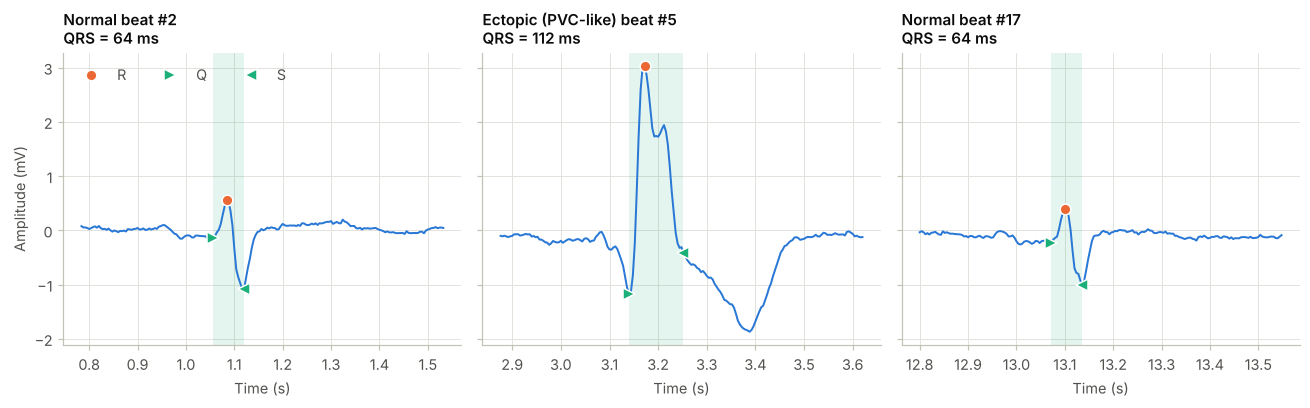

In [19]:
# Step 5.3 — Q, R and S points on example beats | EaindrayMFU26
examples = [(1.0, "Normal beat"), (3.17, "Ectopic (PVC-like) beat"), (13.1, "Normal beat")]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, (tc, name) in zip(axes, examples):
    k = int(np.argmin(np.abs(r60 / FS - tc)))
    m = (t60 >= r60[k] / FS - 0.30) & (t60 <= r60[k] / FS + 0.45)
    ax.axvspan(q60[k] / FS, s60[k] / FS, color=AQUA, alpha=0.12, lw=0)
    ax.plot(t60[m], ecg60_f[m], color=BLUE, lw=1.3)
    ax.plot(r60[k] / FS, ecg60_f[r60[k]], "o", color=ORANGE, ms=7, mec="white", label="R")
    ax.plot(q60[k] / FS, ecg60_f[q60[k]], ">", color=AQUA, ms=8, mec="white", label="Q")
    ax.plot(s60[k] / FS, ecg60_f[s60[k]], "<", color=AQUA, ms=8, mec="white", label="S")
    qrs_ms = (s60[k] - q60[k]) / FS * 1000
    ax.set_title(f"{name} #{k + 1}\nQRS = {qrs_ms:.0f} ms", fontsize=10)
    ax.set_xlabel("Time (s)")
axes[0].set_ylabel("Amplitude (mV)"); axes[0].legend(loc="upper left", ncol=3)
fig.tight_layout(); save(fig, "fig09_qrs_fiducials.png"); plt.show()

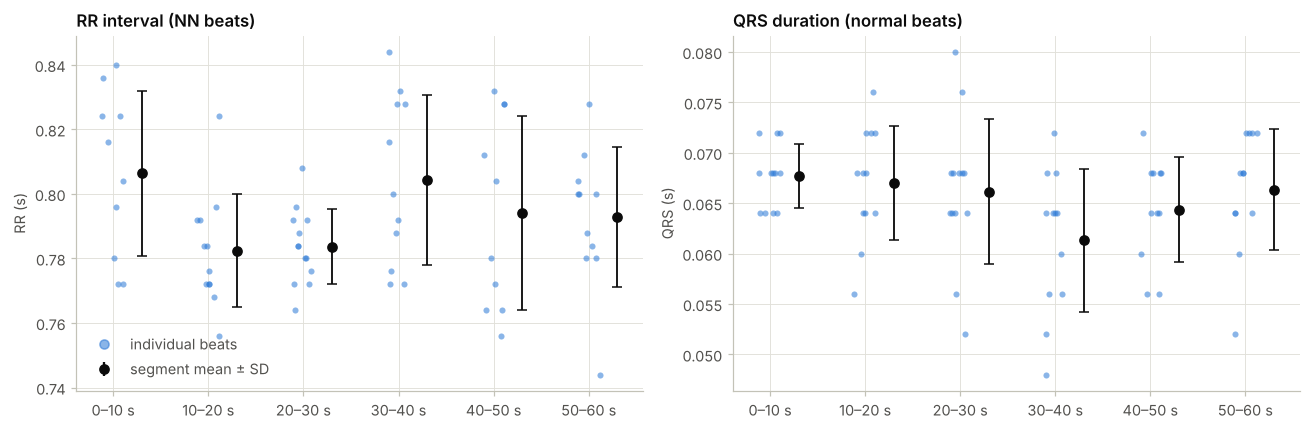

In [20]:
# Step 5.4 — Beat features per segment with segment mean ± SD | EaindrayMFU26
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, use, title in [(axes[0], "RR (s)", feat["NN beat"], "RR interval (NN beats)"),
                            (axes[1], "QRS (s)", is_normal, "QRS duration (normal beats)")]:
    for j, segname in enumerate(SEGMENTS):
        v = feat.loc[use & feat["segment"].eq(segname), col]
        jitter = np.random.default_rng(j).uniform(-0.12, 0.12, v.size)
        ax.plot(j + jitter, v, "o", color=BLUE, ms=4, alpha=0.55, mec="none")
        ax.errorbar(j + 0.3, v.mean(), yerr=v.std(), fmt="o", color=INK, ms=6,
                    capsize=3, lw=1.2)
    ax.set_xticks(range(6), SEGMENTS)
    ax.set(title=title, ylabel=col.replace("(s)", "(s)"))
axes[0].plot([], [], "o", color=BLUE, alpha=0.55, label="individual beats")
axes[0].errorbar([], [], yerr=[], fmt="o", color=INK, label="segment mean ± SD")
axes[0].legend(loc="lower left")
fig.tight_layout(); save(fig, "fig10_segment_features.png"); plt.show()

## Step 6 — Machine-learning classification: Normal vs Arrhythmia

**A. Normal class** – the RR interval and QRS duration of the individual NN beats from Step 5 (label *Normal*).
Individual beat values are used, rather than only the six segment means, because the arrhythmia samples
in the assignment are also *individual beats*: both classes are then described in the same unit
(one sample = one beat) and the data set is reasonably balanced.
**B. Arrhythmia class** – the 50 beats given in the assignment (label *Arrhythmia*).
**C. Model** – Support Vector Machine with RBF kernel (features standardised first), trained on a stratified
70 % / 30 % train/test split. A non-linear kernel is appropriate because arrhythmic beats lie on *both*
sides of the normal RR range (too short *and* too long) – no single straight line in RR can separate them.

label
Normal        67
Arrhythmia    50 

label          Arrhythmia  Normal
RR (s)  count      50.000  67.000
        mean        0.836   0.793
        std         0.492   0.023
        min         0.200   0.744
        25%         0.367   0.774
        50%         0.799   0.788
        75%         1.265   0.810
        max         1.593   0.844
QRS (s) count      50.000  67.000
        mean        0.160   0.065
        std         0.023   0.006
        min         0.120   0.048
        25%         0.141   0.064
        50%         0.164   0.068
        75%         0.176   0.068
        max         0.197   0.080


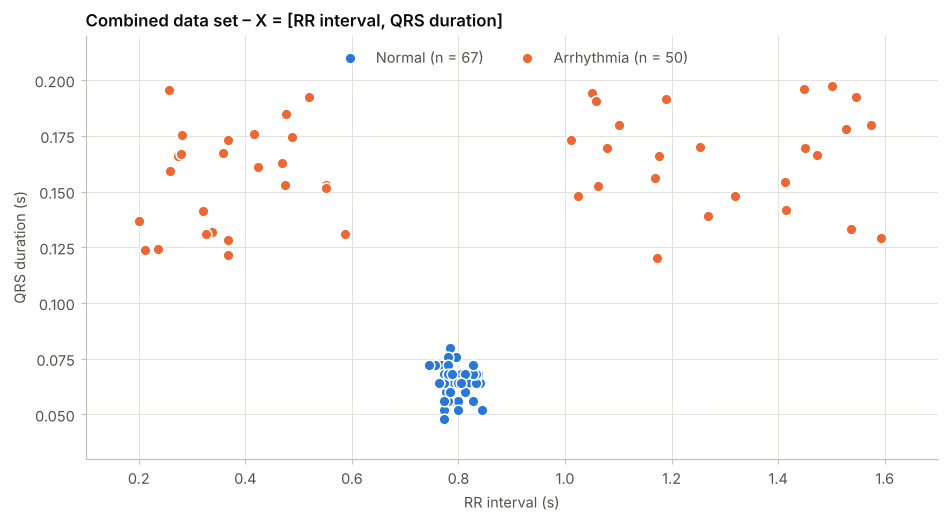

In [21]:
# Step 6.1 — Data set: Normal (Step 5) + Arrhythmia (assignment table) | EaindrayMFU26
nn = feat[feat["NN beat"]]
normal_df = pd.DataFrame({"sample": [f"N{i:02d}" for i in range(1, len(nn) + 1)],
                          "RR (s)": nn["RR (s)"].to_numpy(),
                          "QRS (s)": nn["QRS (s)"].to_numpy(),
                          "label": "Normal", "source": "AHA 0001, ch 2 (Step 5)"})
arr = pd.read_csv(DATA / "arrhythmia_training_data.csv")
arr_df = pd.DataFrame({"sample": [f"A{i:02d}" for i in arr["beat_no"]],
                       "RR (s)": arr["RR_interval_s"], "QRS (s)": arr["QRS_duration_s"],
                       "label": "Arrhythmia", "source": "assignment table"})
dataset = pd.concat([normal_df, arr_df], ignore_index=True)
X = dataset[["RR (s)", "QRS (s)"]].to_numpy()        # X = [RR interval, QRS duration]
y = (dataset["label"] == "Arrhythmia").astype(int).to_numpy()   # 0 = Normal, 1 = Arrhythmia
print(dataset["label"].value_counts().to_string(), "\n")
print(dataset.groupby("label")[["RR (s)", "QRS (s)"]].describe().round(3).T.to_string())

fig, ax = plt.subplots(figsize=(10, 5))
for lab, colr in (("Normal", BLUE), ("Arrhythmia", ORANGE)):
    d = dataset[dataset["label"] == lab]
    ax.plot(d["RR (s)"], d["QRS (s)"], "o", ms=7, color=colr, mec="white", mew=1, ls="none",
            label=f"{lab} (n = {len(d)})")
ax.set(title="Combined data set – X = [RR interval, QRS duration]", xlabel="RR interval (s)",
       ylabel="QRS duration (s)", xlim=(0.1, 1.7), ylim=(0.03, 0.22))
ax.legend(loc="upper center", ncol=2)
save(fig, "fig11_dataset_scatter.png"); plt.show()

In [22]:
# Step 6.2 — Train/test split and model training (SVM, RBF kernel) | EaindrayMFU26
idx = np.arange(len(dataset))
X_tr, X_te, y_tr, y_te, i_tr, i_te = train_test_split(
    X, y, idx, test_size=0.30, stratify=y, random_state=SEED)
model = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale"))
model.fit(X_tr, y_tr)
dataset["split"] = np.where(np.isin(idx, i_te), "test", "train")
dataset.round(5).to_csv(RES / "step6_dataset.csv", index=False)
print(f"Training set: {len(y_tr)} samples (Normal {np.sum(y_tr == 0)}, "
      f"Arrhythmia {np.sum(y_tr == 1)})")
print(f"Test set    : {len(y_te)} samples (Normal {np.sum(y_te == 0)}, "
      f"Arrhythmia {np.sum(y_te == 1)})")
print(f"Support vectors: {model[-1].n_support_.sum()} | training accuracy: "
      f"{model.score(X_tr, y_tr):.3f}")

Training set: 81 samples (Normal 46, Arrhythmia 35)
Test set    : 36 samples (Normal 21, Arrhythmia 15)
Support vectors: 9 | training accuracy: 1.000


In [23]:
# Step 6.3 — Predict the class of the test samples | EaindrayMFU26
names = np.array(["Normal", "Arrhythmia"])
y_pred = model.predict(X_te)
pred_table = dataset.iloc[i_te][["sample", "RR (s)", "QRS (s)", "label"]].copy()
pred_table["predicted"] = names[y_pred]
pred_table["decision score"] = model.decision_function(X_te).round(2)
pred_table["correct"] = pred_table["label"] == pred_table["predicted"]
pred_table = pred_table.sort_values("sample").reset_index(drop=True)
pred_table.round(4).to_csv(RES / "step6_test_predictions.csv", index=False)
print(f"Correct predictions: {pred_table['correct'].sum()} / {len(pred_table)}")
pred_table.round(4)

Correct predictions: 36 / 36


,sample,RR (s),QRS (s),label,predicted,decision score,correct
0,A08,0.3382,0.1317,Arrhythmia,Arrhythmia,1.16,True
1,A10,0.4155,0.1760,Arrhythmia,Arrhythmia,1.26,True
2,A14,0.5512,0.1531,Arrhythmia,Arrhythmia,1.28,True
3,A15,0.2110,0.1240,Arrhythmia,Arrhythmia,1.07,True
4,A16,0.4682,0.1629,Arrhythmia,Arrhythmia,1.33,True
5,A18,0.4235,0.1612,Arrhythmia,Arrhythmia,1.32,True
6,A21,0.5203,0.1923,Arrhythmia,Arrhythmia,1.14,True
7,A23,0.3254,0.1311,Arrhythmia,Arrhythmia,1.16,True
8,A26,1.5368,0.1332,Arrhythmia,Arrhythmia,1.16,True
9,A31,1.0590,0.1907,Arrhythmia,Arrhythmia,1.10,True


                 pred Normal  pred Arrhythmia
true Normal               21                0
true Arrhythmia            0               15 

Accuracy                     1.0
Sensitivity / Recall         1.0
Specificity                  1.0
Precision (PPV)              1.0
F1-score                     1.0
5-fold CV accuracy (mean)    1.0
5-fold CV accuracy (SD)      0.0 

              precision    recall  f1-score   support

      Normal      1.000     1.000     1.000        21
  Arrhythmia      1.000     1.000     1.000        15

    accuracy                          1.000        36
   macro avg      1.000     1.000     1.000        36
weighted avg      1.000     1.000     1.000        36



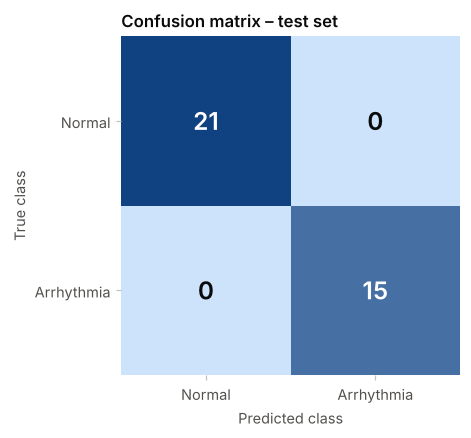

In [24]:
# Step 6.4 — Evaluate: confusion matrix and performance metrics | EaindrayMFU26
cm = confusion_matrix(y_te, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()                 # positive class = Arrhythmia
metrics = pd.Series({"Accuracy": (tp + tn) / cm.sum(),
                     "Sensitivity / Recall": tp / (tp + fn),
                     "Specificity": tn / (tn + fp),
                     "Precision (PPV)": tp / (tp + fp),
                     "F1-score": 2 * tp / (2 * tp + fp + fn)})
cv = cross_val_score(model, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
metrics["5-fold CV accuracy (mean)"], metrics["5-fold CV accuracy (SD)"] = cv.mean(), cv.std()
metrics.round(4).to_csv(RES / "step6_metrics.csv", header=["value"])
print(pd.DataFrame(cm, index=["true Normal", "true Arrhythmia"],
                   columns=["pred Normal", "pred Arrhythmia"]), "\n")
print(metrics.round(4).to_string(), "\n")
print(classification_report(y_te, y_pred, target_names=names, digits=3))

fig, ax = plt.subplots(figsize=(4.6, 4))
ax.imshow(cm, cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list(
    "blue", ["#cde2fb", "#104281"]), vmin=0, vmax=cm.max())
for (a, b), v in np.ndenumerate(cm):
    ax.text(b, a, str(v), ha="center", va="center", fontsize=16, fontweight="semibold",
            color="white" if v > cm.max() / 2 else INK)
ax.set_xticks([0, 1], names); ax.set_yticks([0, 1], names)
ax.set(xlabel="Predicted class", ylabel="True class", title="Confusion matrix – test set")
ax.grid(False); [s.set_visible(False) for s in ax.spines.values()]
save(fig, "fig12_confusion_matrix.png"); plt.show()

Beats excluded from Step 6 (never used for training or testing):
                       beat kind  t_R (s)  RR (s)  QRS (s)   predicted  decision score
beat                                                                                  
5             ectopic (PVC-like)    3.172   0.436    0.112  Arrhythmia            0.70
6     sinus beat after the pause    4.384   1.212    0.072  Arrhythmia            0.24
58            ectopic (PVC-like)   45.280   0.436    0.108  Arrhythmia            0.60
59    sinus beat after the pause   46.428   1.148    0.064      Normal           -0.08
73            ectopic (PVC-like)   57.132   0.456    0.108  Arrhythmia            0.56
74    sinus beat after the pause   58.268   1.136    0.072      Normal           -0.05 



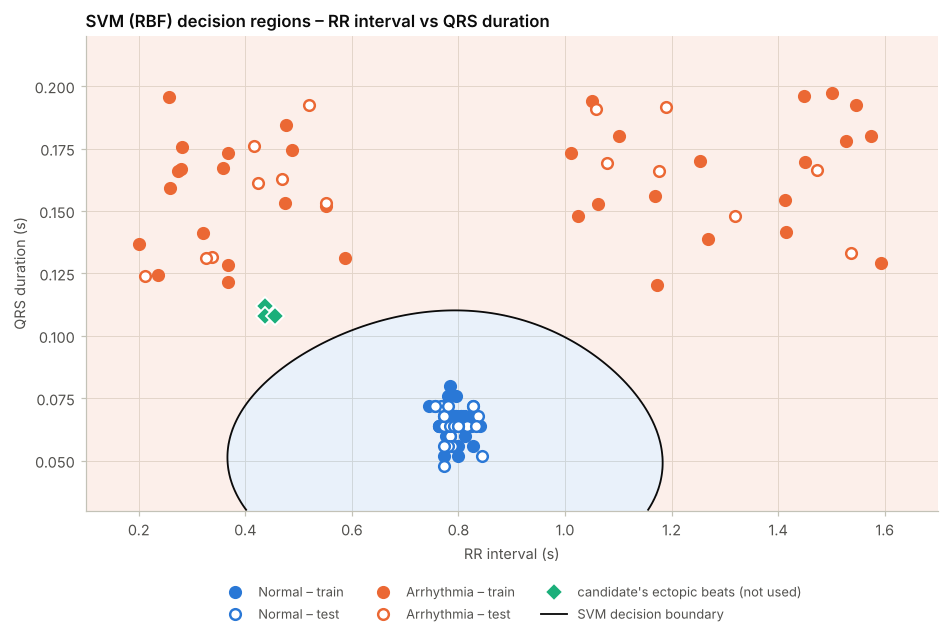

In [25]:
# Step 6.5 — Decision boundary; model applied to the excluded beats | EaindrayMFU26
is_ect = feat["beat type"].eq("Ectopic (PVC-like)")
extra = feat[is_ect | is_ect.shift(1, fill_value=False)][["t_R (s)", "RR (s)", "QRS (s)"]]
extra.insert(0, "beat kind", np.where(is_ect[extra.index], "ectopic (PVC-like)",
                                 "sinus beat after the pause"))
Xe = extra[["RR (s)", "QRS (s)"]].to_numpy()
extra["predicted"], extra["decision score"] = names[model.predict(Xe)], \
    model.decision_function(Xe).round(2)
ect = extra[extra["beat kind"].str.startswith("ectopic")]
extra.round(3).to_csv(RES / "step6_excluded_beats_predictions.csv")
print("Beats excluded from Step 6 (never used for training or testing):")
print(extra.round(3).to_string(), "\n")

gx, gy = np.meshgrid(np.linspace(0.1, 1.7, 400), np.linspace(0.03, 0.22, 400))
Z = model.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
fig, ax = plt.subplots(figsize=(10, 5.6))
ax.contourf(gx, gy, Z > 0, levels=[-0.5, 0.5, 1.5], colors=[BLUE, ORANGE], alpha=0.10)
ax.contour(gx, gy, Z, levels=[0], colors=INK, linewidths=1.2)
for lab, colr in (("Normal", BLUE), ("Arrhythmia", ORANGE)):
    for split, face in (("train", colr), ("test", "white")):
        d = dataset[(dataset["label"] == lab) & (dataset["split"] == split)]
        ax.plot(d["RR (s)"], d["QRS (s)"], "o", ms=7, mfc=face, mec=colr, mew=1.6,
                label=f"{lab} – {split}", ls="none")
ax.plot(ect["RR (s)"], ect["QRS (s)"], "D", ms=8, mfc=AQUA, mec="white", mew=1.2, ls="none",
        label="candidate's ectopic beats (not used)")
ax.plot([], [], color=INK, lw=1.2, label="SVM decision boundary")
ax.set(title="SVM (RBF) decision regions – RR interval vs QRS duration",
       xlabel="RR interval (s)", ylabel="QRS duration (s)", xlim=(0.1, 1.7),
       ylim=(0.03, 0.22))
ax.legend(loc="upper center", ncol=3, fontsize=8.5, bbox_to_anchor=(0.5, -0.13))
save(fig, "fig13_decision_boundary.png"); plt.show()

In [26]:
# Step 6.6 — Robustness check: the six segment means as the Normal class | EaindrayMFU26
X_seg = np.vstack([seg_detail[["RR mean (s)", "QRS mean (s)"]].to_numpy(),
                   arr_df[["RR (s)", "QRS (s)"]].to_numpy()])
y_seg = np.r_[np.zeros(6, int), np.ones(len(arr_df), int)]
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(X_seg, y_seg, test_size=0.30, stratify=y_seg,
                                              random_state=SEED)
m_seg = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale"))
ys_pred = m_seg.fit(Xs_tr, ys_tr).predict(Xs_te)
print(f"Segment-mean version: {len(y_seg)} samples (6 Normal, {len(arr_df)} Arrhythmia)")
print("Confusion matrix (test):\n", confusion_matrix(ys_te, ys_pred, labels=[0, 1]))
print(f"Accuracy: {np.mean(ys_te == ys_pred):.3f}")

Segment-mean version: 56 samples (6 Normal, 50 Arrhythmia)
Confusion matrix (test):
 [[ 2  0]
 [ 0 15]]
Accuracy: 1.000


In [27]:
# Step 7 — Save a summary of all key results | EaindrayMFU26
summary = {
    "student": STUDENT, "record": "ahadb/0001", "channel": CHANNEL + 1, "fs_hz": FS,
    "filter": {"type": "FIR band-stop (Kaiser window)", "numtaps": int(numtaps),
               "beta": round(float(beta), 3), "cutoffs_hz": [F0 - HALF_BW, F0 + HALF_BW],
               "atten_50hz_db_single_pass": round(float(att50), 1),
               **{k: float(v) for k, v in filter_stats.items()}},
    "rpeaks_first10s": int(len(r10)),
    "heart_rate": {"n_peaks": int(n_peaks), "hr_count_bpm": round(float(hr_count), 1),
                   "hr_mean_rr_bpm": round(float(hr_meanrr), 1),
                   "n_ectopic": int((types60 == "Ectopic (PVC-like)").sum()),
                   "n_low_confidence": int((types60 == "Low-confidence (noise)").sum()),
                   "classification": classify_hr(hr_count)},
    "segment_table": table5.to_dict(orient="records"),
    "ml": {"n_normal": int((y == 0).sum()), "n_arrhythmia": int((y == 1).sum()),
           "n_train": int(len(y_tr)), "n_test": int(len(y_te)),
           "confusion_matrix": cm.tolist(), **{k: float(v) for k, v in metrics.items()},
           "ectopic_predictions": ect["predicted"].tolist(),
           "post_pause_predictions": extra.loc[~extra["beat kind"].str.startswith("ectopic"),
                                               "predicted"].tolist(),
           "segment_mean_check_accuracy": float(np.mean(ys_te == ys_pred))}}
(RES / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print(json.dumps(summary["heart_rate"], indent=1, ensure_ascii=False))
print(json.dumps({k: summary["ml"][k] for k in ("confusion_matrix", "Accuracy")}, indent=1))

{
 "n_peaks": 76,
 "hr_count_bpm": 76.0,
 "hr_mean_rr_bpm": 75.6,
 "n_ectopic": 3,
 "n_low_confidence": 1,
 "classification": "Normal"
}
{
 "confusion_matrix": [
  [
   21,
   0
  ],
  [
   0,
   15
  ]
 ],
 "Accuracy": 1.0
}


## Interpretation and conclusion

**Signal processing.** The 281-tap FIR band-stop filter (48–52 Hz, Kaiser window, zero-phase) suppresses the
50-Hz band by ≈ 59 dB without distorting the ECG (correlation with the raw signal 0.9997). The visual change is
negligible because this recording contains very little power-line interference.

**Heart rhythm.** 13 R-peaks were detected in the first 10 s and **76 R-peaks in the full minute →
Heart Rate = 76 bpm (75.6 bpm from the mean RR) → Normal** (60–100 bpm). The rhythm is regular
(normal-to-normal RR 0.744–0.844 s) apart from **three isolated premature, wide, high-amplitude beats** at
3.2 s, 45.3 s and 57.1 s, each followed by a compensatory pause – the typical pattern of premature ventricular
complexes (PVCs). They do not change the heart-rate classification. *(This is a signal-processing exercise,
not a medical diagnosis.)*

**Features.** Per 10-s segment the mean RR interval is 0.78–0.81 s and the mean QRS duration (Q-to-S)
0.061–0.068 s: stable across the minute and well below the 0.12-s limit for a wide QRS.

**Model performance.** On the held-out test set (36 beats) the SVM made **no errors**: confusion matrix
[[21, 0], [0, 15]] → **accuracy = sensitivity = specificity = precision = 100 %**, confirmed by 5-fold
cross-validation (100 %). This is expected, because the two classes do not overlap: every arrhythmia sample
has QRS ≥ 0.120 s (normal ≤ 0.080 s) and an RR interval either < 0.59 s or > 1.01 s (normal 0.744–0.844 s).
The model also labels the candidate's three real ectopic beats – never used for training or testing – as
*Arrhythmia*, which is physiologically consistent.

**Limitations.** (1) The data set is small and perfectly separable, so 100 % should not be expected on new
people. (2) All normal beats come from one person in one minute; neighbouring beats are correlated, so a
random beat-level split is optimistic – a real system must be validated on independent patients.
(3) The model has never seen beats with a *normal* QRS but an *unusual* RR interval: the sinus beats that
follow the compensatory pauses lie on the decision boundary and are classified inconsistently.
(4) The Q-to-S interval underestimates the full QRS duration, and the arrhythmia values may have been measured
with a different method. (5) One beat inside a muscle-noise burst could not be located precisely on channel 2.